# 01. Khám phá dữ liệu (EDA)

**Mục tiêu:** hiểu dữ liệu, chốt cách đặt nhãn, chốt danh sách cột đầu vào, và tìm yếu tố nào thật sự liên quan đến nợ ngủ.

**Dùng thế nào:** chọn kernel `.venv`, bấm *Run All*. Notebook nạp dữ liệu qua `src/preprocess.py` nên tên cột luôn khớp với phần còn lại của dự án.

In [1]:
import sys
sys.path.append("..")          # để import được src/ khi chạy từ thư mục notebooks/

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src.preprocess import *   # FEATURES, TARGET, LABEL_COL, LEAKAGE_COLS, load_raw, load_dataset...

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

raw = load_raw()               # dữ liệu gốc
df = load_dataset()            # đã làm sạch + có cột nhãn nhị phân high_sleep_debt
print("Gốc:", raw.shape, "| Sau làm sạch:", df.shape)

Gốc: (8500, 18) | Sau làm sạch: (8500, 19)


## 1. Tổng quan và chất lượng dữ liệu

In [2]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   str    
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   str    
 3   occupation_type           8500 non-null   str    
 4   chronotype                8500 non-null   str    
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   str    
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_sleep_pct      

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category,high_sleep_debt
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt,1
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt,1
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt,1
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit,0
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt,1


In [3]:
print(raw.isna().sum().sum(), "giá trị thiếu")
print(raw.drop(columns=[ID_COL]).duplicated().sum(), "dòng trùng (không tính user_id)")
df[DECISION_NUMERIC + CONTEXT_NUMERIC].describe().T.round(2)

0 giá trị thiếu
0 dòng trùng (không tính user_id)


,count,mean,std,min,25%,50%,75%,max
bedtime_phone_minutes,8500.0,59.25,36.93,1.0,31.0,51.0,79.0,180.0
screen_brightness_pct,8500.0,55.15,19.85,10.0,42.0,55.0,69.0,100.0
caffeine_post_5pm_mg,8500.0,33.22,51.94,0.0,0.0,0.0,55.0,250.0
physical_activity_min,8500.0,35.70,20.82,0.0,21.0,35.0,50.0,112.0
age,8500.0,34.36,11.58,18.0,25.0,32.0,42.0,65.0


In [4]:
# Các biến phân loại: số giá trị và tỉ lệ từng nhóm
for col in CONTEXT_CATEGORICAL + CONTEXT_ORDINAL + DECISION_CATEGORICAL + DECISION_BINARY:
    print(col, "->", df[col].value_counts(normalize=True).round(3).to_dict())

gender -> {'Female': 0.511, 'Male': 0.459, 'Non-Binary': 0.029}
occupation_type -> {'Corporate 9-to-5': 0.334, 'Remote Tech': 0.252, 'Student': 0.191, 'Healthcare / Shift Worker': 0.117, 'Freelance / Creative': 0.106}
chronotype -> {'Intermediate': 0.456, 'Night Owl': 0.289, 'Morning Lark': 0.255}
primary_bedtime_app -> {'TikTok / Reels': 0.259, 'YouTube': 0.227, 'Instagram / Reddit': 0.192, 'Streaming (Netflix/Hulu)': 0.153, 'Messaging / Chat': 0.1, 'News / Reading': 0.07}
blue_light_filter_active -> {0: 0.532, 1: 0.468}


## 2. Nhãn: `sleep_debt_category`

Nhãn gốc có 4 mức. Bản chính của dự án gộp thành 2 lớp: **nợ ngủ đáng kể** (Moderate Debt + Severe Sleep Debt = 1) so với **không đáng kể** (Optimal Recovery + Mild Deficit = 0).

                        n  ti_le
sleep_debt_category             
Optimal Recovery     1387  0.163
Mild Deficit         2004  0.236
Moderate Debt        4462  0.525
Severe Sleep Debt     647  0.076

Nhãn nhị phân: 1 = 0.601, 0 = 0.399


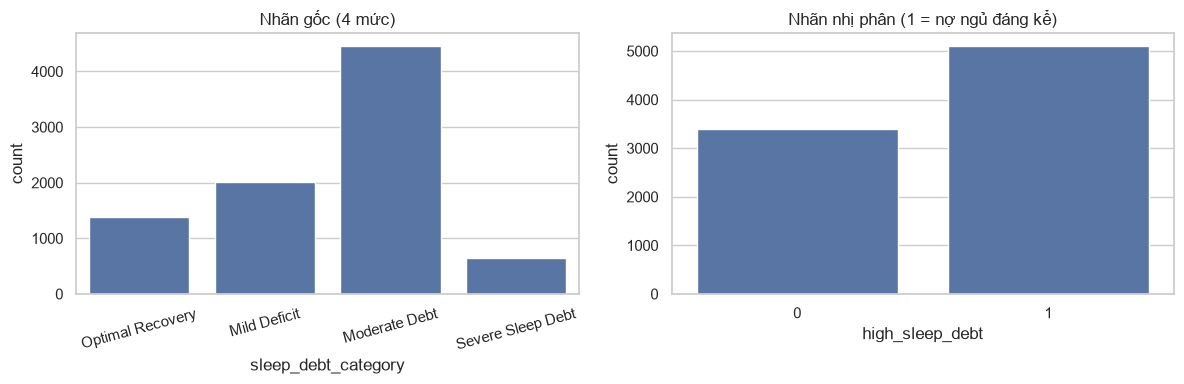

In [5]:
counts = df[LABEL_COL].value_counts().reindex(LABEL_ORDER)
print(pd.DataFrame({"n": counts, "ti_le": (counts / len(df)).round(3)}))
print()
print(f"Nhãn nhị phân: 1 = {df[TARGET].mean():.3f}, 0 = {1 - df[TARGET].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=LABEL_COL, order=LABEL_ORDER, ax=ax[0])
ax[0].set_title("Nhãn gốc (4 mức)")
ax[0].tick_params(axis="x", rotation=15)
sns.countplot(data=df, x=TARGET, ax=ax[1])
ax[1].set_title("Nhãn nhị phân (1 = nợ ngủ đáng kể)")
plt.tight_layout()

## 3. Rò rỉ dữ liệu: vì sao phải loại các cột kết quả giấc ngủ

Các cột `total_sleep_hours`, `sleep_latency_min`, `deep_sleep_pct`, `rem_sleep_pct`, `morning_alarm_snoozes`, `next_day_fatigue_score` là **kết quả** sau một đêm ngủ, không phải thói quen người dùng kiểm soát được. Xem nhãn liên hệ với chúng thế nào:

,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
sleep_debt_category,,,,,,
Optimal Recovery,28.92,8.35,22.37,19.19,0.81,1.08
Mild Deficit,34.69,7.23,22.09,19.16,1.81,1.83
Moderate Debt,42.37,5.55,21.75,19.15,3.35,4.68
Severe Sleep Debt,72.70,3.76,19.18,18.48,5.88,9.58


Khoảng số giờ ngủ theo nhãn:


,min,max
sleep_debt_category,,
Optimal Recovery,7.75,9.80
Mild Deficit,6.75,7.74
Moderate Debt,3.20,6.74
Severe Sleep Debt,3.20,5.38


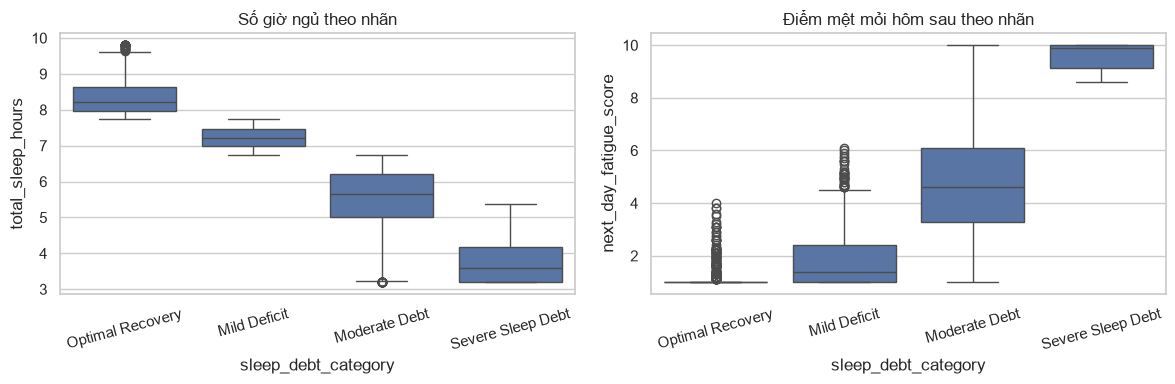

In [6]:
summary = df.groupby(LABEL_COL)[LEAKAGE_COLS].mean().reindex(LABEL_ORDER).round(2)
display(summary)

print("Khoảng số giờ ngủ theo nhãn:")
display(df.groupby(LABEL_COL)["total_sleep_hours"].agg(["min", "max"]).reindex(LABEL_ORDER))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x=LABEL_COL, y="total_sleep_hours", order=LABEL_ORDER, ax=ax[0])
ax[0].set_title("Số giờ ngủ theo nhãn")
ax[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=df, x=LABEL_COL, y="next_day_fatigue_score", order=LABEL_ORDER, ax=ax[1])
ax[1].set_title("Điểm mệt mỏi hôm sau theo nhãn")
ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout()

**Nhận xét:** nhãn gần như được cắt thẳng từ số giờ ngủ (Optimal Recovery từ 7,75 giờ trở lên, Mild Deficit từ 6,75 đến 7,74 giờ). Đưa các cột này vào đầu vào thì mô hình đúng gần tuyệt đối mà vô nghĩa. Vì vậy chúng bị loại khỏi `FEATURES` (có `assert` trong `preprocess.py` canh giữ).

## 4. Phút dùng điện thoại trước khi ngủ

Đây là biến quyết định quan trọng nhất của đề tài.

,ti_le_no_ngu,n
bedtime_phone_minutes,,
0-30,0.360,2051
31-60,0.513,3038
61-90,0.732,1866
91-120,0.907,907
>120,0.978,638


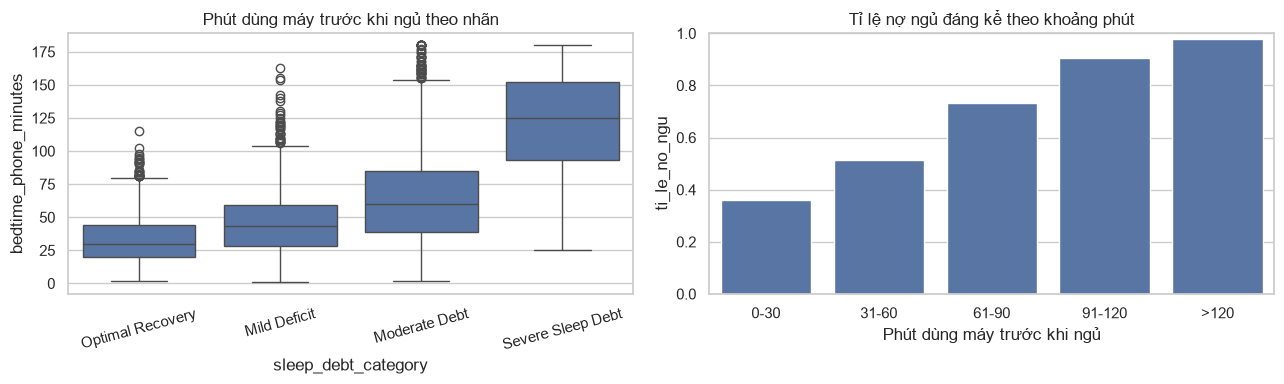

In [7]:
bins = pd.cut(df["bedtime_phone_minutes"], [-1, 30, 60, 90, 120, 181],
              labels=["0-30", "31-60", "61-90", "91-120", ">120"])
rate = df.groupby(bins, observed=True)[TARGET].agg(ti_le_no_ngu="mean", n="count").round(3)
display(rate)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x=LABEL_COL, y="bedtime_phone_minutes", order=LABEL_ORDER, ax=ax[0])
ax[0].set_title("Phút dùng máy trước khi ngủ theo nhãn")
ax[0].tick_params(axis="x", rotation=15)
sns.barplot(x=rate.index.astype(str), y=rate["ti_le_no_ngu"], ax=ax[1])
ax[1].set_title("Tỉ lệ nợ ngủ đáng kể theo khoảng phút")
ax[1].set_xlabel("Phút dùng máy trước khi ngủ")
ax[1].set_ylim(0, 1)
plt.tight_layout()

## 5. Các yếu tố còn lại

Số người theo giới tính: {'Female': 4347, 'Male': 3905, 'Non-Binary': 248}


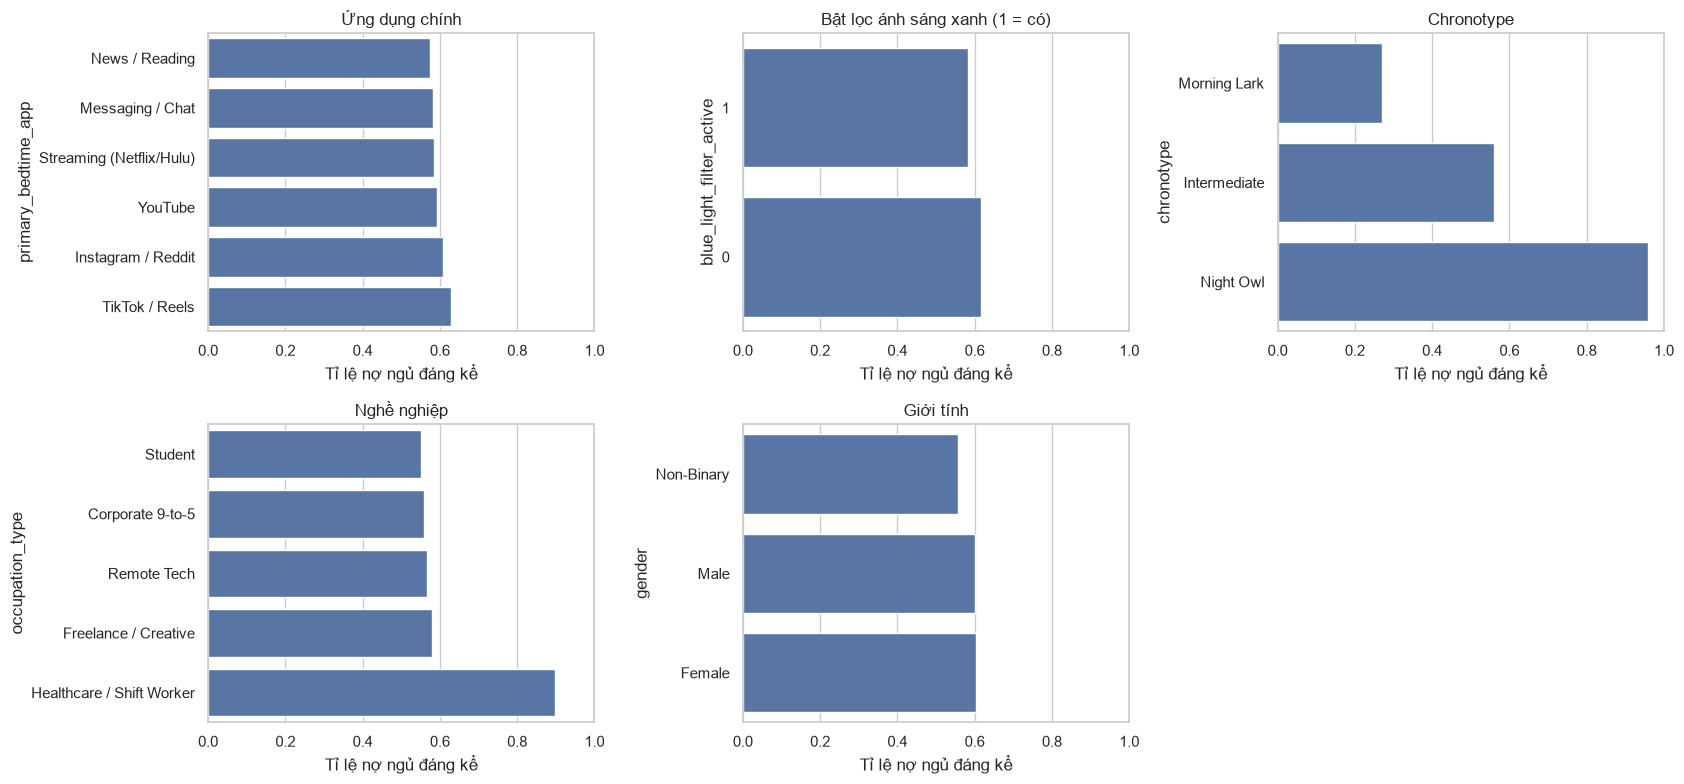

In [8]:
# Tỉ lệ nợ ngủ đáng kể theo từng biến phân loại
factors = [
    ("primary_bedtime_app", "Ứng dụng chính"),
    ("blue_light_filter_active", "Bật lọc ánh sáng xanh (1 = có)"),
    ("chronotype", "Chronotype"),
    ("occupation_type", "Nghề nghiệp"),
    ("gender", "Giới tính"),
]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (col, title) in zip(axes.ravel(), factors):
    r = df.groupby(col)[TARGET].mean().sort_values()
    sns.barplot(x=r.values, y=r.index.astype(str), ax=ax)
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Tỉ lệ nợ ngủ đáng kể")
axes.ravel()[-1].axis("off")
plt.tight_layout()
print("Số người theo giới tính:", df["gender"].value_counts().to_dict())

In [9]:
# Các biến số khác: chia 4 nhóm theo phân vị
rows = []
for col in ["screen_brightness_pct", "caffeine_post_5pm_mg", "physical_activity_min", "age"]:
    q = pd.qcut(df[col], 4, duplicates="drop")
    r = df.groupby(q, observed=True)[TARGET].mean().round(3)
    rows.append(pd.DataFrame({"bien": col, "nhom": r.index.astype(str), "ti_le_no_ngu": r.values}))
display(pd.concat(rows, ignore_index=True))

,bien,nhom,ti_le_no_ngu
0,screen_brightness_pct,"(9.999, 42.0]",0.587
1,screen_brightness_pct,"(42.0, 55.0]",0.611
2,screen_brightness_pct,"(55.0, 69.0]",0.608
3,screen_brightness_pct,"(69.0, 100.0]",0.600
4,caffeine_post_5pm_mg,"(-0.001, 55.0]",0.597
5,caffeine_post_5pm_mg,"(55.0, 250.0]",0.615
6,physical_activity_min,"(-0.001, 21.0]",0.599
7,physical_activity_min,"(21.0, 35.0]",0.603
8,physical_activity_min,"(35.0, 50.0]",0.596
9,physical_activity_min,"(50.0, 112.0]",0.607


## 6. Xếp hạng độ mạnh của từng biến

Mỗi biến được chấm riêng lẻ bằng chỉ số `|2·AUC − 1|` (0 = không phân biệt được gì, 1 = phân biệt hoàn hảo). Với biến phân loại, điểm số là tỉ lệ nhãn 1 của nhóm mà người đó thuộc về.

,bien,loai,do_manh
0,chronotype,ngu canh,0.571
1,bedtime_phone_minutes,quyet dinh,0.496
2,occupation_type,ngu canh,0.159
3,primary_bedtime_app,quyet dinh,0.042
4,blue_light_filter_active,quyet dinh,0.035
5,caffeine_post_5pm_mg,quyet dinh,0.024
6,age,ngu canh,0.015
7,screen_brightness_pct,quyet dinh,0.010
8,gender,ngu canh,0.008
9,physical_activity_min,quyet dinh,0.006


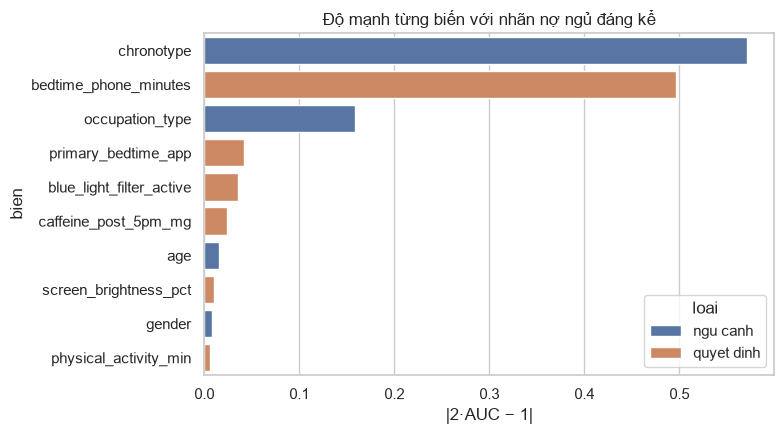

In [10]:
y = df[TARGET]
rows = []
for col in FEATURES:
    if col in DECISION_NUMERIC + CONTEXT_NUMERIC + DECISION_BINARY:
        score = df[col]
    else:
        score = df.groupby(col)[TARGET].transform("mean")
    auc = roc_auc_score(y, score)
    rows.append({
        "bien": col,
        "loai": "quyet dinh" if col in DECISION_VARS else "ngu canh",
        "do_manh": round(abs(2 * auc - 1), 3),
    })
strength = pd.DataFrame(rows).sort_values("do_manh", ascending=False).reset_index(drop=True)
display(strength)

plt.figure(figsize=(8, 4.5))
sns.barplot(data=strength, x="do_manh", y="bien", hue="loai", dodge=False)
plt.title("Độ mạnh từng biến với nhãn nợ ngủ đáng kể")
plt.xlabel("|2·AUC − 1|")
plt.tight_layout()

## 7. Hai yếu tố lớn cộng gộp: chronotype và phút dùng máy

Chronotype và nghề không đổi được, nhưng chúng quyết định **nguy cơ nền** của từng người, nên ảnh hưởng trực tiếp đến những khuyến nghị mà hệ thống đưa ra.

Phút dùng máy trung bình theo chronotype (kiểm tra xem hai yếu tố có đan xen không):
{'Intermediate': 59.6, 'Morning Lark': 59.8, 'Night Owl': 58.3}


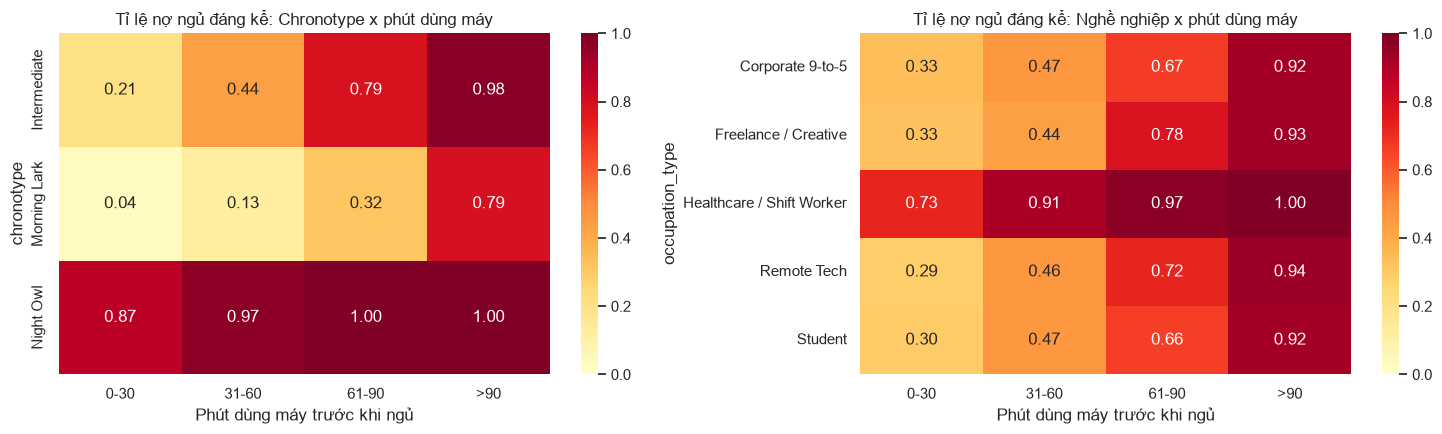

In [11]:
print("Phút dùng máy trung bình theo chronotype (kiểm tra xem hai yếu tố có đan xen không):")
print(df.groupby("chronotype")["bedtime_phone_minutes"].mean().round(1).to_dict())

bins4 = pd.cut(df["bedtime_phone_minutes"], [-1, 30, 60, 90, 181], labels=["0-30", "31-60", "61-90", ">90"])
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, idx, title in [(ax[0], "chronotype", "Chronotype"), (ax[1], "occupation_type", "Nghề nghiệp")]:
    pv = df.pivot_table(index=idx, columns=bins4, values=TARGET, aggfunc="mean", observed=True)
    sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=a)
    a.set_title(f"Tỉ lệ nợ ngủ đáng kể: {title} x phút dùng máy")
    a.set_xlabel("Phút dùng máy trước khi ngủ")
plt.tight_layout()

## 8. Dấu hiệu dữ liệu mô phỏng

Dữ liệu thật thường có các biến liên quan lẫn nhau (người ít vận động có thể dùng máy nhiều hơn...). Kiểm tra xem các biến đầu vào có độc lập một cách bất thường không:

Hệ số tương quan lớn nhất giữa hai biến đầu vào bất kỳ: 0.016


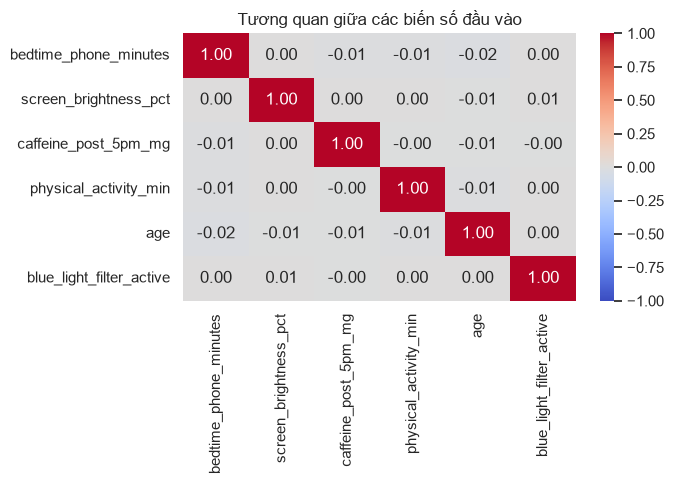

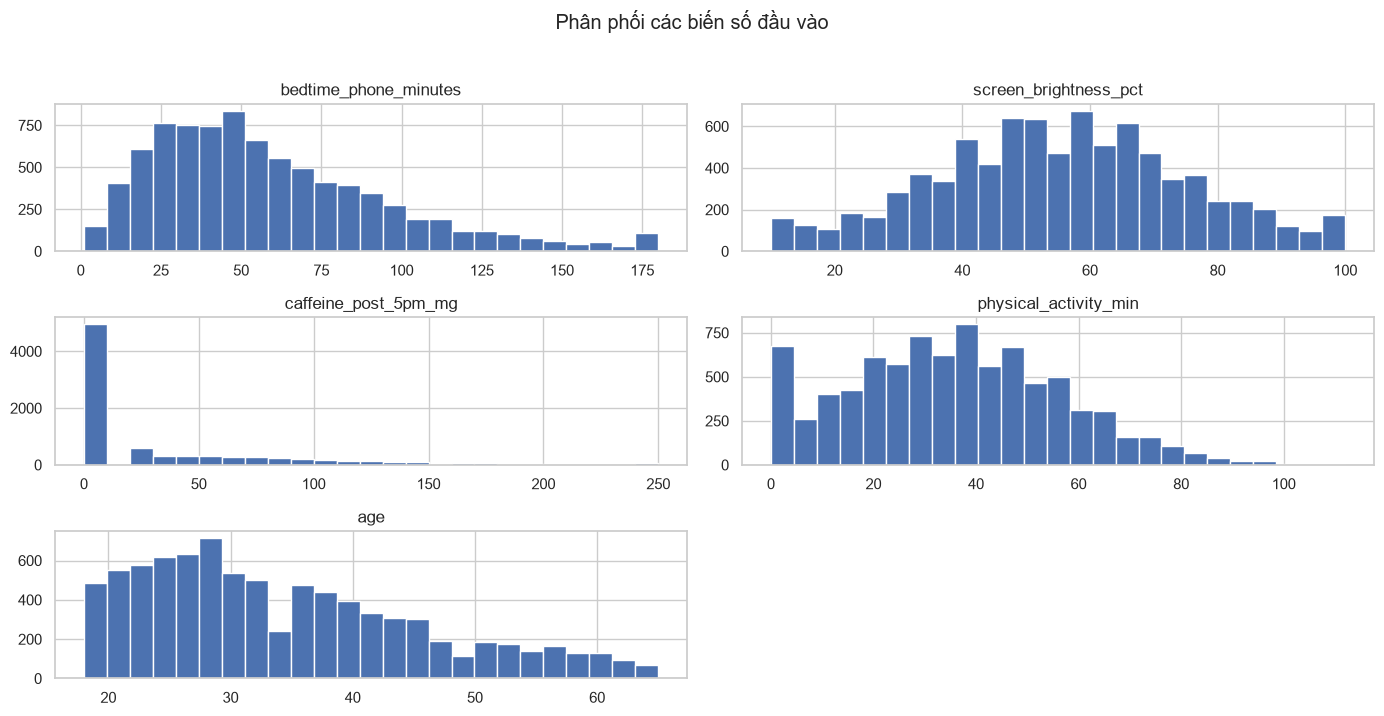

In [12]:
num = DECISION_NUMERIC + CONTEXT_NUMERIC + DECISION_BINARY
corr = df[num].corr()
off = corr.to_numpy().copy()
np.fill_diagonal(off, 0)
print(f"Hệ số tương quan lớn nhất giữa hai biến đầu vào bất kỳ: {np.abs(off).max():.3f}")

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Tương quan giữa các biến số đầu vào")
plt.tight_layout()

df[DECISION_NUMERIC + CONTEXT_NUMERIC].hist(bins=25, figsize=(14, 7))
plt.suptitle("Phân phối các biến số đầu vào", y=1.02)
plt.tight_layout()

## 9. Kết luận cho cả nhóm

**Nhãn.** 60,1% nợ ngủ đáng kể và 39,9% không: khá cân bằng, **chọn nhãn 2 lớp** làm bản chính. Nhãn 4 lớp lệch (Severe Sleep Debt chỉ 7,6%), để làm phần mở rộng.

**Rò rỉ dữ liệu.** Nhãn gần như được cắt thẳng từ `total_sleep_hours`. Loại 6 cột kết quả giấc ngủ khỏi đầu vào; đây là bằng chứng cho slide về rò rỉ dữ liệu.

**Yếu tố mạnh nhất trong các biến người dùng đổi được: phút dùng máy trước khi ngủ.** Tỉ lệ nợ ngủ đáng kể tăng từ khoảng 36% (0-30 phút) lên 51%, 73%, 91% rồi 98% (trên 120 phút).

**Hai yếu tố mạnh nhưng không đổi được: chronotype và nghề.** Night Owl có tỉ lệ nợ ngủ đáng kể khoảng 96%, Intermediate khoảng 56%, Morning Lark khoảng 27%. Nhóm Healthcare / Shift Worker khoảng 90%, các nghề khác 55-58%. Hai yếu tố này không đan xen với phút dùng máy (trung bình khoảng 59 phút ở mọi nhóm), nên cộng gộp độc lập.

**Các biến quyết định còn lại gần như không có tác dụng:** bật lọc ánh sáng xanh (khoảng 58% so với 62%), loại ứng dụng (TikTok / Reels cao nhất khoảng 63%, News / Reading thấp nhất khoảng 58%), độ sáng, caffeine, vận động và tuổi đều có độ mạnh xấp xỉ 0.

**Hệ quả cho phần DSS:**
1. Đòn bẩy thật sự duy nhất là phút dùng máy; những khuyến nghị khác (lọc ánh sáng xanh, đổi ứng dụng, hạ độ sáng) chỉ nên ghi là lợi ích nhỏ, không được phóng đại.
2. Với Night Owl và người làm ca, nguy cơ nền rất cao: ngay cả khi dùng máy dưới 30 phút, Night Owl vẫn khoảng 87%. What-if cần nói thẳng điều này thay vì hứa "giảm xuống mức thấp".
3. 'gender' gần như không liên quan (Female 60,3%, Male 60,1%), nhóm Non-Binary chỉ 248 người. Nhóm quyết định giữ gender trong FEATURES; kiểm tra hiệu năng mô hình theo từng nhóm giới tính và báo cáo kèm lưu ý về cỡ mẫu nhỏ của nhóm Non-Binary.

**Dấu hiệu dữ liệu mô phỏng.** Các biến đầu vào gần như hoàn toàn độc lập nhau (tương quan lớn nhất khoảng 0,02), phân phối trơn, nhãn gần như quyết định bởi một cột. Kết quả chỉ minh họa phương pháp, cần ghi rõ trong phần hạn chế của báo cáo.